In [892]:
import pynq
import xrfdc
import xrfclk
import time
import re
import numpy as np
import pandas as pd
from pathlib import Path
from pynq import Overlay
import matplotlib.pyplot as plt

# 1. Configure Clocks (245.761 MHz External Ref)
custom_lmk_file = "/home/xilinx/jupyter_notebooks/LMK_245_76_ExtRef10.txt"
custom_regs = []
with open(custom_lmk_file, 'r') as f:
    for line in f:
        m = re.search(r'[\t]*(0x[0-9A-F]*)', line.strip('\n'), re.IGNORECASE)
        if m: custom_regs.append(int(m.group(1), 16))

if not xrfclk.xrfclk.lmk_devices or not xrfclk.xrfclk.lmx_devices:
    xrfclk.xrfclk._find_devices()
    xrfclk.xrfclk._read_tics_output()

lmk_chip = xrfclk.xrfclk.lmk_devices[0]['compatible']
xrfclk.xrfclk._Config[lmk_chip][245.761] = custom_regs
xrfclk.set_ref_clks(lmk_freq=245.761, lmx_freq=491.52)
time.sleep(2)

# 2. Load Overlay & Start RFDC
# ol = Overlay("/home/xilinx/Bitfiles/TestingBranch/overlays/TransportPhaseLock.bit")
# ol = Overlay("/home/xilinx/Bitfiles/FFTestingBranch/overlays/TransportPhaseLockFF.bit")
# ol = Overlay("/home/xilinx/Bitfiles/FFIntensityServoBranch/overlays/TransportPhaseLockFF.bit")
ol = Overlay("/home/xilinx/Bitfiles/FreqLocksBranch/overlays/TransportPhaseLockFF.bit")
# ol = Overlay("/home/xilinx/Bitfiles/FFIntensityServoBranch/overlays_backup/overlays/TransportPhaseLockFF.bit")
# ol = Overlay("TransportPhaseLock.bit")
rfdc = ol.usp_rf_data_converter_0
time.sleep(2)

adc_tile = rfdc.adc_tiles[0]
dac_tile = rfdc.dac_tiles[0]

adc_tile.StartUp()
dac_tile.StartUp()
time.sleep(1)

# Verify PLLs
pll_locked = adc_tile.PLLLockStatus
print(f"ADC PLL Locked: {pll_locked}")
print(f"ADC Tile State: {rfdc.IPStatus['ADCTileStatus'][1]['TileState']} (15=Success)")
print(f"DAC Tile State: {rfdc.IPStatus['DACTileStatus'][1]['TileState']} (15=Success)")

ADC PLL Locked: 2
ADC Tile State: 15 (15=Success)
DAC Tile State: 15 (15=Success)


In [594]:
from pathlib import Path
import sys

overlay_dir = Path.cwd()
sys.path.insert(0, str(overlay_dir))
import laser_pll_R7 as laser_pll
import importlib
laser_pll = importlib.reload(laser_pll)
print(laser_pll.__file__)

ol = Overlay("/home/xilinx/Bitfiles/FreqLocksBranch/overlays/TransportPhaseLockFF.bit",download=False)



/home/xilinx/jupyter_notebooks/laser_pll_R7.py


In [714]:
#Disable control loop on startup
loop_en = 0

# loop_en_gpio_1 = ol.axi_gpio_3
loop_en_gpio_2 = ol.axi_gpio_4

# loop_en_gpio_1.channel1.write(loop_en, mask=0b1)
loop_en_gpio_2.channel1.write(loop_en, mask=0b1)

In [711]:
# 1. Set PI Controller Gains

kp = -800
ki = -8
ol.axi_gpio_1.channel1.write(kp, mask=0xFFFF)
ol.axi_gpio_1.channel2.write(ki, mask=0xFFFF)

# 2. Set Gain Bit-Shifts (makes gain parameter smaller by 2^shift)
kp_right_bit_shift = 0
ki_right_bit_shift = 14
ol.axi_gpio_2.channel1.write(kp_right_bit_shift, mask=0b11111)
ol.axi_gpio_2.channel2.write(ki_right_bit_shift, mask=0b11111)




In [715]:
#Reset loop integrator
integrator_rst = 1

integrator_rst_gpio = ol.axi_gpio_4

if integrator_rst:
    integrator_rst_gpio.channel2.write(1, mask=0b1)
    time.sleep(.2)
    integrator_rst_gpio.channel2.write(0,mask=0b1)
print("done")

done


In [713]:
#Enable phase lock loop filter
loop_en = 1


# loop_en_gpio_1 = ol.axi_gpio_3
loop_en_gpio_2 = ol.axi_gpio_4

# loop_en_gpio_1.channel1.write(loop_en, mask=0b1)
loop_en_gpio_2.channel1.write(loop_en, mask=0b1)
print("done")

done


In [10]:
# RMOT control
rmot_freq = 90# In MHz
rmot_amp = 1 # Set between 0 and 1


dac_block = rfdc.dac_tiles[0].blocks[1]
mixer_cfg = dac_block.MixerSettings
mixer_cfg['Freq'] = rmot_freq
dac_block.MixerSettings = mixer_cfg
dac_block.UpdateEvent(xrfdc.EVENT_MIXER)


amp_gpio = int(rmot_amp * 32767)
ol.axi_gpio_12.channel1.write(amp_gpio, mask=0xFFFF)



In [11]:
error_sig_unwrap_en = 0

error_sig_unwrap_gpio = ol.axi_gpio_7

error_sig_unwrap_gpio.channel1.write(error_sig_unwrap_en, mask=0b1)

Normal machine operation should only require the above code blocks. The following are for transfer function measurements

In [127]:
pgen       = ol.perturbation_gen_0
demod_pre  = ol.demod_err_0      # error_signal BEFORE injection (-φ_meas)
demod_post = ol.demod_err_1      # error_signal AFTER injection (e_post)
demod_ctrl = ol.demod_ctrl_0     # PI output (u)

FS_LANE = 245.76e6
FS_EFF  = FS_LANE * 8
FREQ_LSB = (1 << 32) / FS_EFF

# You don't need a perfect guess here anymore. The adaptive function is now 
# clamped to safe small-signal limits (4 to 40 bits).
ESTIMATED_LOOP_BW_HZ = 2000.0

def read_72bit_result(demod, base_name):
    r1 = int(getattr(demod.register_map, f"{base_name}_1"))
    r2 = int(getattr(demod.register_map, f"{base_name}_2"))
    r3 = int(getattr(demod.register_map, f"{base_name}_3"))
    return (r3 << 64) | (r2 << 32) | r1

def s_bits(x, w):
    x = int(x) & ((1 << w) - 1)
    return x - (1 << w) if x & (1 << (w - 1)) else x

def read_complex_result(demod, w=72):
    i_raw = read_72bit_result(demod, 'i_result')
    q_raw = read_72bit_result(demod, 'q_result')
    return s_bits(i_raw, w) + 1j * s_bits(q_raw, w)

def adaptive_amp(freq_hz, loop_bw_hz, base_amp=4, max_amp=40):
    # Scale up amplitude at low frequencies to fight the high loop gain,
    # but clamp it to prevent blasting the phase detector past 2pi (512)
    s_mag = freq_hz / np.sqrt(freq_hz**2 + loop_bw_hz**2)
    amp = base_amp / max(s_mag, 0.1)
    return int(np.clip(amp, base_amp, max_amp))

def adaptive_n_clocks(freq_hz, n_periods=50):
    period_clocks = FS_LANE / freq_hz
    
    # Enforce minimum 0.05s settling time, or 10 periods (whichever is longer)
    n_settle = int(max(0.05 * FS_LANE, 10 * period_clocks))
    
    # Enforce minimum 0.1s measurement time to average out high-frequency noise
    n_measure = int(max(0.1 * FS_LANE, n_periods * period_clocks))
    
    return n_settle, n_measure

def _write_40(rm, base, val):
    setattr(rm, f"{base}_1", val & 0xFFFFFFFF)
    setattr(rm, f"{base}_2", (val >> 32) & 0xFF)

def measure_point(freq_hz, inject_target='err', n_periods=20, base_amp=4):
    freq_word = int(round(freq_hz * FREQ_LSB))
    n_settle, n_measure = adaptive_n_clocks(freq_hz, n_periods=n_periods)

    amp_err = adaptive_amp(freq_hz, ESTIMATED_LOOP_BW_HZ, base_amp) if inject_target=='err' else 0
    amp_nco = adaptive_amp(freq_hz, ESTIMATED_LOOP_BW_HZ, base_amp) if inject_target=='nco' else 0

    rm = pgen.register_map
    rm.freq_word = freq_word
    rm.amp_err   = amp_err
    rm.amp_nco   = amp_nco
    _write_40(rm, "n_clocks_settle",  int(n_settle))
    _write_40(rm, "n_clocks_measure", int(n_measure))

    # Edge trigger start
    rm.start_r = 0
    rm.start_r = 1
    rm.start_r = 0

    expected_s = (n_settle + n_measure) / FS_LANE
    timeout_s = max(2.0 * expected_s, 1.0)

    # Wait for module to enter SETTLING
    t0 = time.time()
    while int(rm.done):
        if time.time() - t0 > 0.1:
            raise RuntimeError("Done signal never cleared after start pulse.")

    # Wait for MEASUREMENT to complete
    t0 = time.time()
    while not int(rm.done):
        if time.time() - t0 > timeout_s:
            # Force modulation off on timeout
            rm.amp_err, rm.amp_nco = 0, 0 
            raise TimeoutError(f"Measurement at {freq_hz:.1f} Hz timed out after {timeout_s:.2f}s")
        time.sleep(min(expected_s / 20, 0.01))
    
    duration = time.time() - t0

    # Latch results
    e_pre  = read_complex_result(demod_pre)
    e_post = read_complex_result(demod_post)
    ctrl   = read_complex_result(demod_ctrl)

    # ZERO THE MODULATION AMPLITUDES SO THE LOOP CAN RECOVER
    rm.amp_err = 0
    rm.amp_nco = 0

    try: ctrl_overflow = int(demod_ctrl.register_map.overflow_flag)
    except AttributeError: ctrl_overflow = 0

    return dict(
        freq_hz=freq_hz, inject_target=inject_target,
        amp_err=amp_err, amp_nco=amp_nco,
        n_settle=n_settle, n_measure=n_measure, duration_s=duration,
        e_pre_I=e_pre.real,   e_pre_Q=e_pre.imag,
        e_post_I=e_post.real, e_post_Q=e_post.imag,
        ctrl_I=ctrl.real,     ctrl_Q=ctrl.imag,
        ctrl_overflow=ctrl_overflow,
    )

In [79]:
freqs = np.logspace(np.log10(10), np.log10(200e3), 200)

results_err_inj = []
print(f"Sweeping {len(freqs)} points, injection at error signal...")
t_start = time.time()

for i, f in enumerate(freqs):
    try:
        r = measure_point(f, inject_target='err')
        results_err_inj.append(r)
        elapsed = time.time() - t_start
        eta = elapsed / (i+1) * (len(freqs) - i - 1)
        print(f"  [{i+1}/{len(freqs)}] {f:>10.1f} Hz  amp={r['amp_err']:>5d}  "
              f"t={r['duration_s']:.3f}s  ETA={eta:.1f}s")
    except TimeoutError as e:
        print(f"  [{i+1}/{len(freqs)}] FAILED: {e}")

df_err = pd.DataFrame(results_err_inj)
print(f"\nTotal sweep time: {time.time() - t_start:.1f} s")

Sweeping 200 points, injection at error signal...
  [1/200]       10.0 Hz  amp=   40  t=3.002s  ETA=604.2s
  [2/200]       10.5 Hz  amp=   40  t=2.859s  ETA=583.9s
  [3/200]       11.0 Hz  amp=   40  t=2.718s  ETA=565.9s
  [4/200]       11.6 Hz  amp=   40  t=2.586s  ETA=549.1s
  [5/200]       12.2 Hz  amp=   40  t=2.465s  ETA=533.2s
  [6/200]       12.8 Hz  amp=   40  t=2.344s  ETA=517.9s
  [7/200]       13.5 Hz  amp=   40  t=2.233s  ETA=503.3s
  [8/200]       14.2 Hz  amp=   40  t=2.122s  ETA=489.0s
  [9/200]       14.9 Hz  amp=   40  t=2.020s  ETA=475.3s
  [10/200]       15.7 Hz  amp=   40  t=1.919s  ETA=462.1s
  [11/200]       16.4 Hz  amp=   40  t=1.829s  ETA=449.3s
  [12/200]       17.3 Hz  amp=   40  t=1.738s  ETA=436.9s
  [13/200]       18.2 Hz  amp=   40  t=1.657s  ETA=425.0s
  [14/200]       19.1 Hz  amp=   40  t=1.576s  ETA=413.5s
  [15/200]       20.1 Hz  amp=   40  t=1.495s  ETA=402.4s
  [16/200]       21.1 Hz  amp=   40  t=1.424s  ETA=391.6s
  [17/200]       22.2 Hz  amp= 

In [128]:
def compute_transfer_functions(df):
    """From raw I/Q data, derive L, P, C."""
    e_pre  = df['e_pre_I']  + 1j*df['e_pre_Q']
    e_post = df['e_post_I'] + 1j*df['e_post_Q']
    ctrl   = df['ctrl_I']   + 1j*df['ctrl_Q']

    L = -e_pre / e_post     # Open-loop transfer function
    P = e_pre / ctrl        # Plant alone
    C = ctrl / e_post       # Controller

    # Use np.real() and np.imag() to handle Pandas Series correctly
    return pd.DataFrame({
        'freq_hz': df['freq_hz'],
        'L_mag': np.abs(L), 'L_phase_deg': np.angle(L, deg=True),
        'P_mag': np.abs(P), 'P_phase_deg': np.angle(P, deg=True),
        'C_mag': np.abs(C), 'C_phase_deg': np.angle(C, deg=True),
        'L_real': np.real(L), 'L_imag': np.imag(L),
        'P_real': np.real(P), 'P_imag': np.imag(P),
        'C_real': np.real(C), 'C_imag': np.imag(C),
    })

tf_err = compute_transfer_functions(df_err)

# Save Data
timestamp = time.strftime("%Y%m%d_%H%M%S")
out_dir = Path("sweep_data")
out_dir.mkdir(exist_ok=True)
df_err.to_csv(out_dir / f"sweep_err_inj_{timestamp}.csv", index=False)
tf_err.to_csv(out_dir / f"transfer_functions_{timestamp}.csv", index=False)

# Plotting
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for col, (label, mag_key, ph_key) in enumerate([
    ('L = open-loop', 'L_mag', 'L_phase_deg'),
    ('P = plant',     'P_mag', 'P_phase_deg'),
    ('C = controller','C_mag', 'C_phase_deg'),
]):
    ax_m, ax_p = axes[0, col], axes[1, col]
    ax_m.semilogx(tf_err['freq_hz'], 20*np.log10(tf_err[mag_key]))
    ax_m.set_ylabel(f'|{label}| (dB)')
    ax_m.grid(True, which='both')
    ax_m.axhline(0, color='k', lw=0.5)

    phase_unwrap = np.unwrap(np.deg2rad(tf_err[ph_key])) * 180/np.pi
    ax_p.semilogx(tf_err['freq_hz'], phase_unwrap)
    ax_p.set_ylabel(f'∠ {label} (deg)')
    ax_p.grid(True, which='both')
    ax_p.axhline(-180, color='r', lw=0.5)
    ax_p.set_xlabel('Frequency (Hz)')

plt.tight_layout()
plt.savefig(out_dir / f"bode_{timestamp}.png", dpi=150)
plt.show()

# Phase Margin
L_complex = tf_err['L_real'].to_numpy() + 1j*tf_err['L_imag'].to_numpy()
mag_db = 20*np.log10(np.abs(L_complex))
xover_idx = np.argmin(np.abs(mag_db))
f_xover = tf_err['freq_hz'].iloc[xover_idx]
pm = 180 + np.angle(L_complex[xover_idx], deg=True)

print(f"\nGain crossover: {f_xover:.0f} Hz")
print(f"Phase margin:   {pm:.1f}°")

NameError: name 'df_err' is not defined

In [81]:
print(df_err)

           freq_hz inject_target  amp_err  amp_nco   n_settle  n_measure  \
0        10.000000           err       40        0  245760000  491520000   
1        10.510254           err       40        0  233828789  467657579   
2        11.046544           err       40        0  222476818  444953637   
3        11.610199           err       40        0  211675965  423351931   
4        12.202614           err       40        0  201399474  402798949   
..             ...           ...      ...      ...        ...        ...   
195  163899.312337           err        4        0   12288000   24576000   
196  172262.342039           err        4        0   12288000   24576000   
197  181052.098765           err        4        0   12288000   24576000   
198  190290.356437           err        4        0   12288000   24576000   
199  200000.000000           err        4        0   12288000   24576000   

     duration_s       e_pre_I       e_pre_Q      e_post_I      e_post_Q  \
0      3.001

In [182]:
df_err.to_csv('PhaseLockXfer.csv', index = False)

In [129]:
import matplotlib.pyplot as plt
import numpy as np
from pynq import allocate

phase_dma_gpio = ol.axi_gpio_3

cycles_to_capture = 64

phase_dma_gpio.channel1.write(cycles_to_capture, mask=0xFFFFFFFF)
phase_dma_gpio.channel2.write(cycles_to_capture, mask=0xFFFFFFFF)



0x0
Capture complete


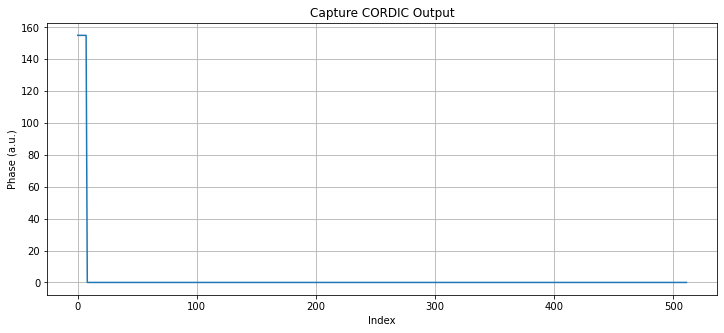

In [1261]:
total_samples = cycles_to_capture * 8
buffer = allocate(shape=(total_samples,),dtype=np.int16)

#0 if 85 MHz, 1 if 170
dma_sw = 1

if dma_sw:
    dma = ol.axi_dma_0
else:
    dma = ol.axi_dma_1
print(dma.register_map.S2MM_DMASR)
dma.recvchannel.transfer(buffer)
dma.recvchannel.wait()

print("Capture complete")

plt.figure(figsize=(12,5))
plt.plot(buffer)
plt.title(f"Capture CORDIC Output")
plt.xlabel("Index")
plt.ylabel("Phase (a.u.)")
plt.grid(True)

np.savetxt("170_MHz_mon.csv", buffer, delimiter=",")
plt.show()



In [1262]:
import matplotlib.pyplot as plt
import numpy as np
from pynq import allocate

error_dma_gpio = ol.axi_gpio_5

cycles_to_capture = 64

error_dma_gpio.channel1.write(cycles_to_capture, mask=0xFFFFFFFF)



0x0
Capture complete


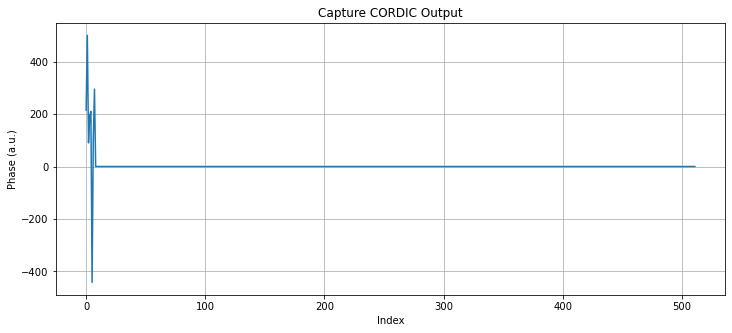

In [1263]:
total_samples = cycles_to_capture * 8
buffer = allocate(shape=(total_samples,),dtype=np.int16)

dma = ol.axi_dma_2

print(dma.register_map.S2MM_DMASR)
dma.recvchannel.transfer(buffer)
dma.recvchannel.wait()

print("Capture complete")

plt.figure(figsize=(12,5))
plt.plot(buffer)
plt.title(f"Capture CORDIC Output")
plt.xlabel("Index")
plt.ylabel("Phase (a.u.)")
plt.grid(True)

np.savetxt("Error_sig_mon_closed_loop_2.csv", buffer, delimiter=",")
plt.show()



In [130]:
DMA_MAX_BYTES = (1 << 26) - 1
BYTES_PER_IQ_BEAT = 16

def setup_dma_buffer(duration_s, sample_rate_hz):
    num_beats = int(round(duration_s * sample_rate_hz))
    nbytes = num_beats * BYTES_PER_IQ_BEAT
    assert nbytes <= DMA_MAX_BYTES, f"Too large: {nbytes} > {DMA_MAX_BYTES}"
    print(f"Allocating {nbytes/1e6:.2f} MB, {num_beats} DMA beats")
    return allocate(shape=(num_beats, 2), dtype=np.int64)

def s2mm_status(dma):
    s = int(dma.register_map.S2MM_DMASR)
    flags = []
    for bit, name in [(0,"halted"), (1,"idle"), (4,"DMAIntErr"), (5,"DMASlvErr"),
                      (6,"DMADecErr"), (12,"IOC"), (14,"ErrIRQ")]:
        if s & (1 << bit):
            flags.append(name)
    return f"0x{s:08x} {' '.join(flags)}"

def execute_clean_capture(overlay, dma_buffer):
    dma = overlay.axi_dma_3
    gpio = overlay.axi_gpio_13
    num_beats = int(dma_buffer.shape[0])
    assert dma_buffer.nbytes == num_beats * BYTES_PER_IQ_BEAT

    gpio.channel1.write(1, mask=0x1)
    gpio.channel2.write(num_beats, mask=0xFFFFFFFF)

    dma_buffer[:] = 0
    dma_buffer.flush()

    print("S2MM before:", s2mm_status(dma))
    dma.recvchannel.transfer(dma_buffer)
    print("S2MM armed: ", s2mm_status(dma))

    gpio.channel1.write(1, mask=0x1)
    dma.recvchannel.wait()

    dma_buffer.invalidate()
    print("S2MM after: ", s2mm_status(dma))
    return dma_buffer

In [131]:
import h5py 
import time
from pynq import allocate, Overlay

def save_and_compress(dma_buffer, filename, sample_rate_hz):
    print(f"Compressing and saving to {filename}...")
    
    i_data = dma_buffer[:, 0]
    q_data = dma_buffer[:, 1]
    
    with h5py.File(filename, "w") as f:
        f.create_dataset("I_channel", data = i_data, compression = "gzip", compression_opts=4)
        f.create_dataset("Q_channel", data = q_data, compression = "gzip", compression_opts=4)
        
        f.attrs["sample_rate_hz"] = sample_rate_hz
        f.attrs["duration_s"] = dma_buffer.shape[0] / sample_rate_hz
        f.attrs["timestamp"] = time.strftime("%Y-%m-%d %H:%M:%s")
        f.attrs["notes"] = "Filtered and captured mixed down beat note"
        
    print(f"Saved successfully")
    
    dma_buffer.freebuffer()

In [150]:
fs_out = 960e3
capture_seconds = 4.0

buffer = setup_dma_buffer(capture_seconds, fs_out)
buffer = execute_clean_capture(ol, buffer)
save_and_compress(buffer, "PSD_data", 960e3)

Allocating 61.44 MB, 3840000 DMA beats
S2MM before: 0x00001002 idle IOC
S2MM armed:  0x00001000 IOC
S2MM after:  0x00001002 idle IOC
Compressing and saving to PSD_data...
Saved successfully


In [151]:
fs_out = 960e3
capture_seconds = 4.0
num_samples = int(fs_out * capture_seconds)

ol.axi_gpio_13.channel1.write(0, mask=0xFFFFFFFF)
ol.axi_gpio_13.channel2.write(num_samples, mask=0xFFFFFFFF)

buffer = setup_dma_buffer(duration_s=capture_seconds, sample_rate_hz = fs_out)
buffer[:] = 0

ol.axi_dma_3.recvchannel.transfer(buffer)
print("DMA armed and waiting")

ol.axi_gpio_13.channel1.write(1, 0xFFFFFFFF)

ol.axi_dma_3.recvchannel.wait()
print("Capture complete")

print(buffer)
print(len(buffer))

save_and_compress(buffer, "PSD_data_1_ghz_injected_upstream", 960e3)

Allocating 61.44 MB, 3840000 DMA beats
DMA armed and waiting
Capture complete
[[ -9236254080577874 -52146653303817234]
 [ -9500055234204167 -52026653083997074]
 [ -9671989377731376 -52157892646186103]
 ...
 [ -9554755500511676 -52173019769231381]
 [ -9759920509944262 -52189433158756570]
 [ -9998748538559522 -52050260047065787]]
3840000
Compressing and saving to PSD_data_1_ghz_injected_upstream...
Saved successfully


In [152]:
buffer.freebuffer()

In [900]:
def ones_complement_fixed_to_decimal(value: int, int_bits: int, total_width: int) -> float:
    if int_bits < 1:
        raise ValueError("int_bits must include the sign bit, so it must be at least 1.")

    if total_width <= int_bits:
        raise ValueError("total_width must be greater than int_bits for fixed-point fractional bits.")

    if value < 0 or value >= (1 << total_width):
        raise ValueError("value does not fit in total_width bits.")

    frac_bits = total_width - int_bits
    sign_bit = 1 << (total_width - 1)

    is_negative = bool(value & sign_bit)

    if is_negative:
        # In 1's complement, negative value is bitwise complement of magnitude.
        magnitude_bits = (~value) & ((1 << total_width) - 1)
        magnitude = magnitude_bits / (1 << frac_bits)
        return -magnitude
    else:
        return value / (1 << frac_bits)
    

In [901]:
def decimal_to_ones_complement_fixed(x: float, int_bits: int, total_width: int) -> int:
    if int_bits < 1:
        raise ValueError("int_bits must include the sign bit, so it must be at least 1.")

    if total_width <= int_bits:
        raise ValueError("total_width must be greater than int_bits for fixed-point fractional bits.")

    frac_bits = total_width - int_bits
    scale = 1 << frac_bits
    max_raw_magnitude = (1 << (total_width - 1)) - 1
    max_value = max_raw_magnitude / scale

    if abs(x) > max_value:
        raise ValueError(f"value out of range for this format: valid range is {-max_value} to {max_value}")

    # Quantize to fixed-point integer magnitude.
    raw_magnitude = round(abs(x) * scale)

    if raw_magnitude > max_raw_magnitude:
        raise ValueError(f"value out of range after quantization: valid range is {-max_value} to {max_value}")

    if x < 0:
        # 1's-complement negative encoding is bitwise complement of positive magnitude.
        mask = (1 << total_width) - 1
        return (~raw_magnitude) & mask

    return raw_magnitude

raw = decimal_to_ones_complement_fixed(2.25, 3 , 16)
print(f"{raw:016b}")

0100100000000000


In [902]:
# Set phase correction to 0 to measure phase delay e.g., due to cable length

phase_correction = decimal_to_ones_complement_fixed(0.0, 3, 16) & 0xFFFF
print(f"phase_correction = 0b{phase_correction:016b}")
ol.axi_gpio_10.channel1.write(phase_correction, mask=0xFFFF)

phase_correction = 0b0000000000000000


In [903]:
import matplotlib.pyplot as plt
import numpy as np
from pynq import allocate

error_dma_gpio = ol.axi_gpio_8

cycles_to_capture = 8192

error_dma_gpio.channel1.write(cycles_to_capture, mask=0xFFFFFFFF)



0x1002
Capture complete
phase_offset = 0b0000000100100011
0.0355224609375


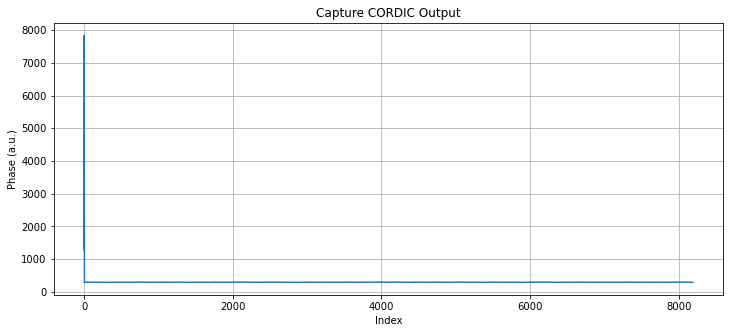

In [905]:
total_samples = cycles_to_capture
buffer = allocate(shape=(total_samples,),dtype=np.int16)

dma = ol.axi_dma_4

print(dma.register_map.S2MM_DMASR)
dma.recvchannel.transfer(buffer)
dma.recvchannel.wait()

print("Capture complete")

plt.figure(figsize=(12,5))
plt.plot(buffer)
plt.title(f"Capture CORDIC Output")
plt.xlabel("Index")
plt.ylabel("Phase (a.u.)")
plt.grid(True)

mean_int = int(np.trunc(np.mean(buffer)))
phase_offset_raw = mean_int & 0xFFFF
phase_offset = ones_complement_fixed_to_decimal(phase_offset_raw, 3, 16) # in rad
print(f"phase_offset = 0b{phase_offset_raw:016b}")
print(phase_offset)

plt.show()




In [906]:
phase_correction = decimal_to_ones_complement_fixed(phase_offset, 3, 16) & 0xFFFF


print(f"phase_correction = 0b{phase_correction:016b}")

ol.axi_gpio_10.channel1.write(phase_correction, mask=0xFFFF)

phase_correction = 0b0000000100100011


0x1002
Capture complete
phase_offset = 0b0000000000000000
0.0


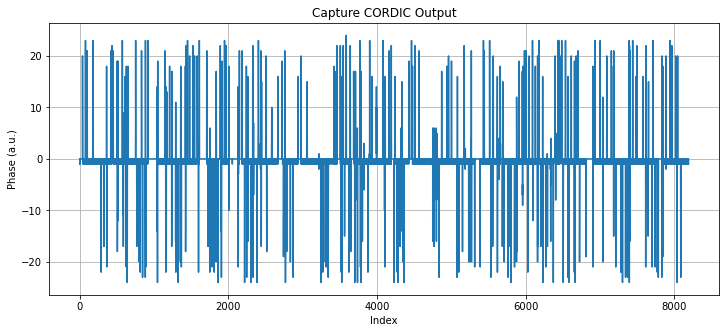

In [908]:
# Measure phase again after correction 
total_samples = cycles_to_capture
buffer = allocate(shape=(total_samples,),dtype=np.int16)

dma = ol.axi_dma_4

print(dma.register_map.S2MM_DMASR)
dma.recvchannel.transfer(buffer)
dma.recvchannel.wait()

print("Capture complete")

plt.figure(figsize=(12,5))
plt.plot(buffer)
plt.title(f"Capture CORDIC Output")
plt.xlabel("Index")
plt.ylabel("Phase (a.u.)")
plt.grid(True)

mean_int = int(np.trunc(np.mean(buffer)))
phase_offset_raw = mean_int & 0xFFFF
phase_offset = ones_complement_fixed_to_decimal(phase_offset_raw, 3, 16) # in rad
print(f"phase_offset = 0b{phase_offset_raw:016b}")
print(phase_offset)

plt.show()




In [893]:
# Demod mixer ctrl
demod_freq = 89.99999999998603 # In MHz
# demod_freq = 80
demod_phase = 0

adc_block = rfdc.adc_tiles[0].blocks[1]
mixer_cfg = adc_block.MixerSettings
mixer_cfg['Freq'] = demod_freq
# mixer_cfg['PhaseOffset'] = demod_phase
adc_block.MixerSettings = mixer_cfg
adc_block.UpdateEvent(xrfdc.EVENT_MIXER)
print(adc_block.MixerSettings)



{'Freq': 89.99999999998603, 'PhaseOffset': 0.0, 'EventSource': 2, 'CoarseMixFreq': 0, 'MixerMode': 3, 'FineMixerScale': 0, 'MixerType': 2}


In [894]:
# TP LO control
lo_freq = 89.99999999999302# In MHz
lo_amp = 0.25 # Set between 0 and 1

dac_block = rfdc.dac_tiles[0].blocks[1]
mixer_cfg = dac_block.MixerSettings
mixer_cfg['Freq'] = lo_freq
dac_block.MixerSettings = mixer_cfg
dac_block.UpdateEvent(xrfdc.EVENT_MIXER)


amp_gpio = int(lo_amp * 32767)
ol.axi_gpio_12.channel1.write(amp_gpio, mask=0xFFFF)



In [895]:
dac_block = rfdc.dac_tiles[0].blocks[1]
mixer_cfg = dac_block.MixerSettings
print(mixer_cfg)

{'Freq': 89.99999999998603, 'PhaseOffset': 0.0, 'EventSource': 2, 'CoarseMixFreq': 0, 'MixerMode': 2, 'FineMixerScale': 0, 'MixerType': 2}


In [896]:
tp_intensity_open_loop = False # False # 

if tp_intensity_open_loop: 
    ol.axi_gpio_9.channel1.write(0b1, mask=0xFFFF)
else:
    ol.axi_gpio_9.channel1.write(0b0, mask=0xFFFF)

In [897]:
# TP control
tp_freq = 80
tp_amp = 0.85 # Set between 0 and 1
dac_block = rfdc.dac_tiles[0].blocks[3]
mixer_cfg = dac_block.MixerSettings
mixer_cfg['Freq'] = tp_freq
dac_block.MixerSettings = mixer_cfg
dac_block.UpdateEvent(xrfdc.EVENT_MIXER)

amp_gpio = int(tp_amp * 32767)
ol.axi_gpio_9.channel2.write(amp_gpio, mask=0xFFFF)

In [898]:
tp_controller = ol.fast_servo_controller_0
print(tp_controller.register_map)
tp_en_addr = tp_controller.register_map.loop_en.address
tp_Kp_addr = tp_controller.register_map.Kp.address
tp_Ki_addr = tp_controller.register_map.Ki.address

Kp_float = -1
Ki_float = -0.005

frac_bit_shift = 2**18

Kp_fixed = round(Kp_float * frac_bit_shift)
Ki_fixed = round(Ki_float * frac_bit_shift)

tp_controller.write(tp_en_addr, 0x01)
tp_controller.write(tp_Kp_addr, Kp_fixed)
tp_controller.write(tp_Ki_addr, Ki_fixed)
print(tp_controller.read(tp_Ki_addr))
print(tp_controller.read(tp_Kp_addr))

RegisterMap {
  loop_en = Register(loop_en=write-only, RESERVED=write-only),
  adc_bias = Register(adc_bias=write-only, RESERVED=write-only),
  dac_bias = Register(dac_bias=write-only, RESERVED=write-only),
  Kp = Register(Kp=write-only, RESERVED=write-only),
  Ki = Register(Ki=write-only, RESERVED=write-only)
}
268434145
268173312


In [2611]:
tp_adc_offset_read_gpio = ol.axi_gpio_15
print(tp_adc_offset_read_gpio.channel1.read())

65498


In [2482]:
tp_bias_amp = 0.00 # 32 mW or so
tp_bias_bits = int(tp_bias_amp * 32767)
tp_dac_bias_addr = tp_controller.register_map.dac_bias.address
tp_controller.write(tp_dac_bias_addr, tp_bias_bits)

In [899]:
# TP manual setpoint control
tp_servo_manual_setpoint_en =  False#False # 
tp_servo_manual_setpoint = 500 # 0

if tp_servo_manual_setpoint_en: 
    ol.axi_gpio_11.channel1.write(0b1, mask=0xFFFF)
else:
    ol.axi_gpio_11.channel1.write(0b0, mask=0xFFFF)
    
ol.axi_gpio_11.channel2.write(int(tp_servo_manual_setpoint), mask=0xFFFF)
    

In [699]:
tp_servo_manual_setpoint = 100
ol.axi_gpio_11.channel2.write(int(tp_servo_manual_setpoint), mask=0xFFFF)

In [134]:
import numpy as np

PL_CLK_HZ = 245.76e6
N_LANES = 8
NCO_SAMPLE_RATE_HZ = PL_CLK_HZ * N_LANES

def smoothstep(x):
    # Quintic smooth ramp waveform
    return 10.0*x**3 - 15.0*x**4 + 6.0*x**5

def freq_hz_to_fcw_offset(freq_offset_hz, sample_rate_hz = NCO_SAMPLE_RATE_HZ):
    signed = np.rint(freq_offset_hz / sample_rate_hz * 2**32).astype(np.int64)
    return (signed & 0xFFFFFFFF).astype(np.uint32)

def pack_dwell_command_64(fcw_u32, dwell_cycles_u32):
    # bits [63:32] frequency control word
    # bits [31:0] how many PL clocks to hold control word
    return ((np.uint64(fcw_u32) & np.uint64(0xFFFFFFFF)) << np.uint64(32)) | (np.uint64(dwell_cycles_u32) & np.uint64(0xFFFFFFFF))

def pack_dwell_command_32(fcw_u16, dwell_cycles_u16):
    # bits [63:32] frequency control word
    # bits [31:0] how many PL clocks to hold control word
    return ((np.uint64(fcw_u16) & np.uint32(0xFFFF)) << np.uint32(16)) | (np.uint32(dwell_cycles_u16) & np.uint32(0xFFFF))


def seconds_to_cycles(duration_s, pl_clk_hz = PL_CLK_HZ):
    cycles = int(round(duration_s * pl_clk_hz))
    if duration_s > 0 and cycles < 1:
        cycles = 1
    return cycles

In [135]:
def generate_transport_offset_commands_64(
    ramp_det_hz,
    tramp_s,
    hold_s,
    ramp_dt_s = 1.0e-6,
    pl_clk_hz = PL_CLK_HZ,
    sample_rate_hz = NCO_SAMPLE_RATE_HZ):
    """
    Sequence has 3 stages: (1) freq ramp (2) const detuning hold (3) ramp back to zero
    
    Sample freq ramp at ramp_dt intervals, hold constant with one freq word
    """
    ramp_cycles_per_step = seconds_to_cycles(ramp_dt_s, pl_clk_hz)
    actual_ramp_dt_s = ramp_cycles_per_step / pl_clk_hz
    
    n_ramp_steps = int(np.ceil(tramp_s / actual_ramp_dt_s))
    
    if n_ramp_steps < 1:
        n_ramp_steps = 1
        
    ramp_step_cycles = np.full(n_ramp_steps, ramp_cycles_per_step, dtype=np.uint32)
    total_ramp_cycles_target = seconds_to_cycles(tramp_s, pl_clk_hz)
    excess_cycles = int(np.sum(ramp_step_cycles, dtype=np.uint64)) - total_ramp_cycles_target
    
    if excess_cycles > 0:
        ramp_step_cycles[-1] = np.uint32(max(1, int(ramp_step_cycles[-1]) - excess_cycles))
        
    x = np.arange(n_ramp_steps, dtype=np.float64) / n_ramp_steps
    s = smoothstep(x)
    
    ramp_down_offset_hz = -ramp_det_hz * s
    ramp_up_offset_hz = -ramp_det_hz * (1.0 - s)
    
    commands = []
    
    fcw_down = freq_hz_to_fcw_offset(ramp_down_offset_hz, sample_rate_hz)
    for fcw, dwell in zip(fcw_down, ramp_step_cycles):
        commands.append(pack_dwell_command_64(fcw, dwell))
        
    hold_cycles = seconds_to_cycles(hold_s, pl_clk_hz)
    if hold_cycles > 0:
        fcw_hold = freq_hz_to_fcw_offset(-ramp_det_hz, sample_rate_hz)
        commands.append(pack_dwell_command_64(fcw_hold, hold_cycles))
        
    fcw_up = freq_hz_to_fcw_offset(ramp_up_offset_hz, sample_rate_hz)
    for fcw, dwell in zip(fcw_up, ramp_step_cycles):
        commands.append(pack_dwell_command_64(fcw, dwell))
        
    return np.asarray(commands, dtype = np.uint64)



In [136]:
from pynq import allocate

def load_dwell_commands_to_dma_64(dma, commands_u64):
    buf = allocate(shape=(len(commands_u64),), dtype=np.uint64)
    buf[:] = commands_u64
    buf.flush()
    
    dma.sendchannel.transfer(buf)
    return buf

def load_dwell_commands_to_dma_32(dma, commands_u32):
    buf = allocate(shape=(len(commands_u32),), dtype=np.uint32)
    buf[:] = commands_u32
    buf.flush()
    
    dma.sendchannel.transfer(buf)
    return buf

In [1285]:
ramp_det_hz = 1819281.69
tramp_s = .019
transport_duration = .19
hold_s = transport_duration - 2*tramp_s
ramp_dt_s = 1.0e-6

commands = generate_transport_offset_commands_64(
    ramp_det_hz = ramp_det_hz,
    tramp_s = tramp_s,
    hold_s = hold_s,
    ramp_dt_s = ramp_dt_s)

print(f"{len(commands)} commands")
print(f"{commands.nbytes / 1024:.1f} kB")

37965 commands
296.6 kB


In [137]:
cmd_buf = load_dwell_commands_to_dma(ol.axi_dma_5, commands)
ol.axi_dma_5.sendchannel.wait() # waits for TTL pulse on pmod pin

NameError: name 'load_dwell_commands_to_dma' is not defined

In [1286]:
# dwell streamer testing 
# 64-bit
commands = []
for x in range(10):
    commands.append(pack_dwell_command_64(freq_hz_to_fcw_offset(10000 * x, NCO_SAMPLE_RATE_HZ), np.uint32(10 + x)))
print(commands)
cmd_array = np.asarray(commands, dtype = np.uint64)
for cmd in cmd_array:
    print(hex(cmd))
                    

[10, 93823560581131, 187651416129548, 281474976710669, 375298537291790, 469126392840207, 562949953421328, 656773514002449, 750601369550866, 844424930131987]
0xa
0x55550000000b
0xaaab0000000c
0x100000000000d
0x155550000000e
0x1aaab0000000f
0x2000000000010
0x2555500000011
0x2aaab00000012
0x3000000000013


In [139]:
# 32-bit
pl_clk_period = 4.07e-9
factor = 10e-3 / (pl_clk_period * 100) 
commands = []
for x in range(100):
    for y in range(100):
        if x <= 50:
            commands.append(pack_dwell_command_32(np.uint16(x + 3), np.uint16(factor)))
        else: 
            commands.append(pack_dwell_command_32(np.uint16(103 - x), np.uint16(factor)))
# print(commands)

cmd_array_32 = np.asarray(commands, dtype = np.uint32)
# for cmd in cmd_array_32:
#     print(hex(cmd))
print(f"{len(cmd_array_32)} commands")
print(f"{cmd_array_32.nbytes / 1024:.1f} kB")

10000 commands
39.1 kB


In [717]:
#USE THIS FOR RESET
cmd_buf_32 = load_dwell_commands_to_dma_32(ol.axi_dma_6, cmd_array_32)
ol.axi_dma_6.sendchannel.wait()
ol.axi_gpio_14.channel2.write(0x1, mask=0x1)

ol.axi_gpio_14.channel2.write(0x0, mask=0x1)

In [2441]:
cmd_buf = load_dwell_commands_to_dma_64(ol.axi_dma_5, cmd_array)
ol.axi_dma_5.sendchannel.wait()

ol.axi_gpio_14.channel1.write(0x1, mask=0x1)

ol.axi_gpio_14.channel1.write(0x0, mask=0x1)

In [27]:
# Matisse SRS replacement control
mat_freq = 800.01 # In MHz


dac_block = rfdc.dac_tiles[1].blocks[2]
mixer_cfg = dac_block.MixerSettings
mixer_cfg['Freq'] = mat_freq
dac_block.MixerSettings = mixer_cfg
dac_block.UpdateEvent(xrfdc.EVENT_MIXER)





In [66]:
def generate_linear_ramp_commands_64(
        end_offset_hz,
        tramp_s,
        ramp_dt_s=1.0e-6,
        pl_clk_hz=PL_CLK_HZ,
        sample_rate_hz=NCO_SAMPLE_RATE_HZ):
    """
    Single-stage linear frequency ramp: NCO offset goes 0 -> end_offset_hz
    over tramp_s, resampled every ramp_dt_s (quantized to PL clock cycles).

    Total dwell across all commands == seconds_to_cycles(tramp_s).
    """
    step_cycles = seconds_to_cycles(ramp_dt_s, pl_clk_hz)
    actual_dt_s = step_cycles / pl_clk_hz

    n_steps = max(1, int(np.ceil(tramp_s / actual_dt_s)))

    dwell_cycles = np.full(n_steps, step_cycles, dtype=np.uint32)

    # trim the last step so the sequence length matches tramp_s exactly
    total_target_cycles = seconds_to_cycles(tramp_s, pl_clk_hz)
    excess = int(np.sum(dwell_cycles, dtype=np.uint64)) - total_target_cycles
    if excess > 0:
        dwell_cycles[-1] = np.uint32(max(1, int(dwell_cycles[-1]) - excess))

    # linear 0 -> 1, endpoint inclusive
    x = np.zeros(1) if n_steps == 1 else \
        np.arange(n_steps, dtype=np.float64) / (n_steps - 1)

    offset_hz = end_offset_hz * x

    fcw = freq_hz_to_fcw_offset(offset_hz, sample_rate_hz)
    commands = [pack_dwell_command_64(f, d)
                for f, d in zip(fcw, dwell_cycles)]

    return np.asarray(commands, dtype=np.uint64)

NameError: name 'PL_CLK_HZ' is not defined

In [650]:
#LP AOM drive center frequency
lp_freq_mhz = 80
lp_freq_fcw = int(freq_hz_to_fcw_offset(lp_freq_mhz * 10**6, NCO_SAMPLE_RATE_HZ))
channel = ol.axi_gpio_16.channel1
channel._val = int(channel._val)
channel.write(lp_freq_fcw, mask=0xFFFFFFFF)

In [2753]:

#LP dispersive shift chirp, load then trigger in BLACs
chirp_freq_mhz = 10
chirp_duration_s = 4*46e-6
ramp_dt = 20e-9

cmd_buf_64_lp = generate_linear_ramp_commands_64(chirp_freq_mhz * 10**6, chirp_duration_s, ramp_dt, sample_rate_hz = NCO_SAMPLE_RATE_HZ)
cmd_buf_64_lp = load_dwell_commands_to_dma_64(ol.axi_dma_7, cmd_buf_64_lp)
ol.axi_dma_7.sendchannel.wait()


In [87]:

adc_block = rfdc.adc_tiles[0].blocks[3]
mixer_cfg = adc_block.MixerSettings
print(mixer_cfg['Freq'])




966.0800000000024


In [109]:
post_rfdc_mix_en = False
channel = ol.axi_gpio_13.channel1
channel.write(post_rfdc_mix_en, mask=0b1)

In [28]:
# DC-coupled test
dc_freq = 1e-3
# dc_freq = 1e-6# In MHz
dc_phase = 0


dac_block = rfdc.dac_tiles[1].blocks[1]
mixer_cfg = dac_block.MixerSettings
print(mixer_cfg)
mixer_cfg['Freq'] = dc_freq
mixer_cfg['PhaseOffset'] = dc_phase
dac_block.MixerSettings = mixer_cfg
dac_block.UpdateEvent(xrfdc.EVENT_MIXER)





{'Freq': 0.0, 'PhaseOffset': -109.99923706054688, 'EventSource': 2, 'CoarseMixFreq': 0, 'MixerMode': 2, 'FineMixerScale': 0, 'MixerType': 2}


In [770]:
reference_hz = laser_pll.configure(
    ol,
    reference_frequency_hz=800e6,
    phase_offset_rad=0.0,
    phase_gain_shift=0,       # phase gain = 1
    capture_gain_shift=6,     # frequency-term weight = 64
    minimum_amplitude=64,
    invert=True,           
)

laser_pll.configure_acquisition(
    ol,
    stage=1,
    coarse_gain_shift=0,
    transition_interval_log2=2,  # at most ~4.27 ms for a full-span handoff
    minimum_fft_peak=32,
)

print("Reference:", reference_hz / 1e6, "MHz")
print(laser_pll.acquisition_status(ol))

Reference: 800.0000000000024 MHz
{'stage': 0, 'dc_test': False, 'transitioning': False, 'pending': True, 'near_ready': False, 'fine_ready': False, 'output_valid': False, 'remembered_turns': 0, 'fft_frequency_hz': 935040000.0, 'fft_valid': True, 'fft_weak': False, 'fft_overflow_seen': False, 'fft_protocol_fault': False, 'fft_frame': 186}


In [771]:
laser_pll.enable(ol)

In [772]:
# Acquisition stage 1: coarse FFT
acq = laser_pll.acquisition_status(ol)
assert acq["fft_valid"], "No qualified FFT tone: check the input and FFT status."

laser_pll.enable(ol)
print(laser_pll.acquisition_status(ol))

{'stage': 1, 'dc_test': False, 'transitioning': False, 'pending': False, 'near_ready': False, 'fine_ready': True, 'output_valid': True, 'remembered_turns': 0, 'fft_frequency_hz': 935040000.0, 'fft_valid': True, 'fft_weak': False, 'fft_overflow_seen': False, 'fft_protocol_fault': False, 'fft_frame': 211}


In [773]:
# Acquisition stage 2: phase + frequency error signal
acq = laser_pll.select_stage(ol, 2, timeout_s=5.0)
print(acq)

fine = laser_pll.status(ol)
print("Reference − beat:", fine["frequency_error_hz"] / 1e6, "MHz")
print("Fine phase valid:", fine["valid"])

{'stage': 2, 'dc_test': False, 'transitioning': False, 'pending': False, 'near_ready': True, 'fine_ready': True, 'output_valid': True, 'remembered_turns': 0, 'fft_frequency_hz': 802560000.0, 'fft_valid': True, 'fft_weak': False, 'fft_overflow_seen': False, 'fft_protocol_fault': False, 'fft_frame': 219}
Reference − beat: 12.19125 MHz
Fine phase valid: True


In [774]:
# Acquisition stage 3: unwrapped phase only

fine = laser_pll.status(ol)
print("Reference − beat:", fine["frequency_error_hz"] / 1e6, "MHz")
print("Fine phase valid:", fine["valid"])


acq = laser_pll.select_stage(ol, 3, timeout_s=5.0)
print(acq)

print("Remembered turns:", acq["remembered_turns"])
print(laser_pll.status(ol))

Reference − beat: 7.768125 MHz
Fine phase valid: True
{'stage': 3, 'dc_test': False, 'transitioning': False, 'pending': False, 'near_ready': True, 'fine_ready': True, 'output_valid': True, 'remembered_turns': -1737, 'fft_frequency_hz': 787200000.0, 'fft_valid': True, 'fft_weak': False, 'fft_overflow_seen': False, 'fft_protocol_fault': False, 'fft_frame': 237}
Remembered turns: -1737
{'phase_error_rad': 1.8359832555006268, 'frequency_error_hz': -17336250.0, 'enabled': True, 'valid': True, 'saturated': True, 'dac_stall_seen': False}


In [495]:
# Adjust gains
laser_pll.set_gains(ol, phase_gain_shift=0, capture_gain_shift=0)


In [496]:
# Bypass FFT bound requirement 

laser_pll.enable(ol, False)
laser_pll.configure_acquisition(ol, stage=0)
laser_pll.enable_capture(ol, True)
laser_pll.enable(ol)

In [728]:
# Disable
laser_pll.enable(ol, False)

In [498]:
adc = ol.usp_rf_data_converter_0.adc_tiles[0].blocks[3]

print("Before:", adc.NyquistZone, adc.CalibrationMode)
# PYNQ: Nyquist 1=odd, 2=even; calibration 0=AutoCal, 1=Mode1, 2=Mode2

adc.NyquistZone = 1

print("After:", adc.NyquistZone, adc.CalibrationMode)

Before: 1 2
After: 1 2


In [775]:
laser_pll.set_tracking_gain(ol, 0, wait=False)
laser_pll.select_stage(ol, 4)

{'stage': 4,
 'dc_test': False,
 'transitioning': False,
 'pending': False,
 'near_ready': True,
 'fine_ready': True,
 'output_valid': True,
 'remembered_turns': -2,
 'fft_frequency_hz': 800640000.0,
 'fft_valid': True,
 'fft_weak': False,
 'fft_overflow_seen': False,
 'fft_protocol_fault': False,
 'fft_frame': 224}

In [776]:
laser_pll.set_tracking_gain(ol, 1)  # 2× slope; ~11.9 ms default ramp

{'initialized': True,
 'ramping': False,
 'saturated': False,
 'valid': True,
 'gain_relative_to_stage3': 2.0,
 'target_shift': 1}

In [641]:
laser_pll.set_tracking_gain(ol, 3)

{'initialized': True,
 'ramping': False,
 'saturated': False,
 'valid': True,
 'gain_relative_to_stage3': 8.0,
 'target_shift': 3}

In [279]:
print("Helper:", laser_pll.__file__)
print("Stage-3 divisor:", getattr(laser_pll, "STAGE3_PHASE_DIVISOR", "old helper"))
print("Loaded FPGA version:", hex(ol.pll_acquisition_status.read(0x08) >> 24))

Helper: /home/xilinx/jupyter_notebooks/laser_pll_R6.py
Stage-3 divisor: 160
Loaded FPGA version: 0xa6


In [208]:
iq = laser_pll.capture_iq(ol, samples=262144, decimation_log2=4) # hi freq

In [704]:
iq = laser_pll.capture_iq(
    ol, samples=262144, decimation_log2=4) #lo freq

In [705]:
import numpy as np
from scipy.signal import welch
import time 
for i in range(10):
    iq = laser_pll.capture_iq(
    ol, samples=262144, decimation_log2=4)
    np.savez("laser_iq_PLL_shortest_" + str(i) + ".npz", **iq)
    print(i)

    phase_rad = np.unwrap(np.angle(
        iq["i_adc_counts"] + 1j * iq["q_adc_counts"]
    ))
    frequency_hz, phase_psd = welch(
        phase_rad,
        fs=iq["sample_rate_hz"],
        nperseg=min(65536, len(phase_rad)),
        detrend="constant",
        scaling="density",
    )

    np.savetxt(
        "laser_phase_psd.csv",
        np.column_stack((frequency_hz, phase_psd)),
        delimiter=",",
        header="frequency_Hz,phase_PSD_rad2_per_Hz",
        comments="",
    )
    

0
1
2
3
4
5
6
7
8
9


In [530]:
laser_pll.set_dc_output(ol, 100)
laser_pll.enable(ol)

In [736]:
# 1482 PLL ref tone 
pll_freq = 0 # In MHz


dac_block = rfdc.dac_tiles[0].blocks[2]
mixer_cfg = dac_block.MixerSettings
mixer_cfg['Freq'] = pll_freq
dac_block.MixerSettings = mixer_cfg
dac_block.UpdateEvent(xrfdc.EVENT_MIXER)



